# 03 · Customer Segmentation (RFM + Behaviour, K-means)

**Business question:** marketing has budget for a targeted coupon program starting 2023-09-01.
Which customers should get it?

The model is trained on **Feb 1 – Aug 31 data only** (what was known at decision time).
Feature engineering and clustering live in `src/segmentation.py`, so the exact same pipeline is
reused everywhere.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

import db
import plot_style as ps
import segmentation as seg

ps.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
con = db.connect()

behavior = con.execute("SELECT * FROM behavior").df()
orders = con.execute("SELECT * FROM orders").df()
customers = con.execute("SELECT * FROM customers").df()

## 1. Feature engineering
One row per customer who visited at least once by Aug 31.

In [2]:
CUTOFF = "2023-08-31"
features = seg.build_features(behavior, orders, customers, CUTOFF)
print(f"{len(features):,} customers, {len(seg.FEATURES)} features")
features[seg.FEATURES].describe().T.round(2)

13,772 customers, 9 features


,count,mean,std,min,25%,50%,75%,max
recency_days,13772.0,30.32,49.17,0.00,3.00,9.00,26.00,211.00
visits_per_30d,13772.0,3.00,2.03,0.14,1.53,2.64,4.12,17.31
orders_per_30d,13772.0,0.28,0.43,0.00,0.00,0.14,0.40,5.55
avg_order_value,13772.0,65.47,73.50,0.00,0.00,54.51,105.40,684.66
visit_to_order,13772.0,0.10,0.13,0.00,0.00,0.05,0.16,1.00
pv_per_visit,13772.0,4.05,1.03,1.00,3.33,3.75,4.93,10.00
coupon_share,13772.0,0.22,0.36,0.00,0.00,0.00,0.33,1.00
promo_order_share,13772.0,0.15,0.30,0.00,0.00,0.00,0.17,1.00
tenure_days,13772.0,187.11,51.71,14.00,211.00,211.00,211.00,211.00


| Feature | Meaning |
|---|---|
| recency_days | days since last visit |
| visits_per_30d / orders_per_30d | visit and purchase frequency, normalised by tenure |
| avg_order_value | monetary value |
| visit_to_order | how often a visit turns into an order |
| pv_per_visit | browsing depth |
| coupon_share / promo_order_share | price sensitivity |
| tenure_days | how long the customer has been with the store |

Skewed features (frequency, value, recency, tenure) are log-transformed, then all features are standardised.

## 2. Choosing k

In [3]:
Xs = seg.transform(features)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Xs)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(Xs, km.labels_, sample_size=5000, random_state=0)})
k_scores = pd.DataFrame(rows)
k_scores.round(3)

,k,inertia,silhouette
0,2,89534.002,0.277
1,3,73213.707,0.274
2,4,62099.213,0.279
3,5,53520.058,0.308
4,6,47370.464,0.308
5,7,43474.944,0.305
6,8,40094.197,0.300


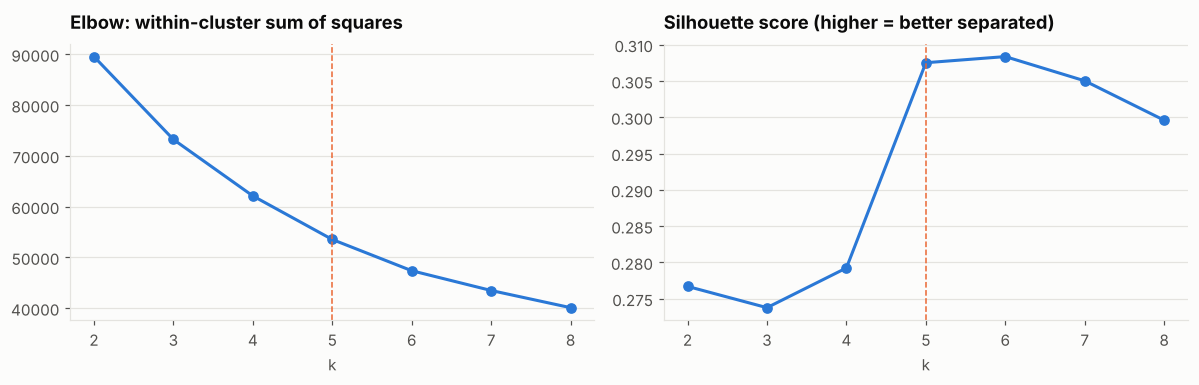

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_scores["k"], k_scores["inertia"], marker="o", color=ps.BLUE)
axes[0].set_title("Elbow: within-cluster sum of squares")
axes[1].plot(k_scores["k"], k_scores["silhouette"], marker="o", color=ps.BLUE)
axes[1].set_title("Silhouette score (higher = better separated)")
for ax in axes:
    ax.axvline(5, color=ps.ORANGE, lw=1, ls="--")
    ax.set_xlabel("k")
fig.tight_layout()
ps.save(fig, "03_choose_k")

The silhouette score reaches its high plateau at **k = 5**, and 5 segments are still small enough for
marketing to act on, so k = 5 is chosen.

## 3. Fit and name the segments

In [5]:
labels, km, Xs = seg.fit_segments(features, k=5)
names = seg.name_clusters(features, labels)
features["segment"] = labels.map(names)

profile = features.groupby("segment").agg(
    customers=("visits", "size"),
    recency_days=("recency_days", "median"),
    visits_per_30d=("visits_per_30d", "median"),
    orders_per_30d=("orders_per_30d", "mean"),
    avg_order_value=("avg_order_value", "median"),
    visit_to_order_pct=("visit_to_order", lambda s: s.mean() * 100),
    pv_per_visit=("pv_per_visit", "median"),
    coupon_share_pct=("coupon_share", lambda s: s.mean() * 100),
    promo_order_share_pct=("promo_order_share", lambda s: s.mean() * 100),
    tenure_days=("tenure_days", "median"),
)
gmv = (orders[(orders.order_status == "completed") & (pd.to_datetime(orders.order_date) <= CUTOFF)]
       .groupby("customer_id")["net_amount"].sum())
features["gmv_feb_aug"] = gmv.reindex(features.index).fillna(0)
profile["share_of_customers_pct"] = profile["customers"] / profile["customers"].sum() * 100
profile["share_of_gmv_pct"] = features.groupby("segment")["gmv_feb_aug"].sum() / features["gmv_feb_aug"].sum() * 100
ORDER = ["High-Value Loyal", "Deal Seekers", "New Potential", "Window Shoppers", "Dormant / At-Risk"]
profile = profile.loc[ORDER]
profile.round(1).T

segment,High-Value Loyal,Deal Seekers,New Potential,Window Shoppers,Dormant / At-Risk
customers,3247.0,2876.0,892.0,3427.0,3330.0
recency_days,5.0,9.0,5.0,4.0,87.0
visits_per_30d,3.3,2.6,2.7,4.1,0.9
orders_per_30d,0.8,0.3,0.0,0.1,0.0
avg_order_value,151.2,68.0,0.0,0.0,0.0
visit_to_order_pct,24.1,13.6,0.1,1.1,4.4
pv_per_visit,3.5,3.6,3.9,5.5,3.5
coupon_share_pct,18.9,80.1,0.0,2.2,0.2
promo_order_share_pct,12.5,58.1,0.0,1.6,0.0
tenure_days,211.0,211.0,43.0,211.0,211.0


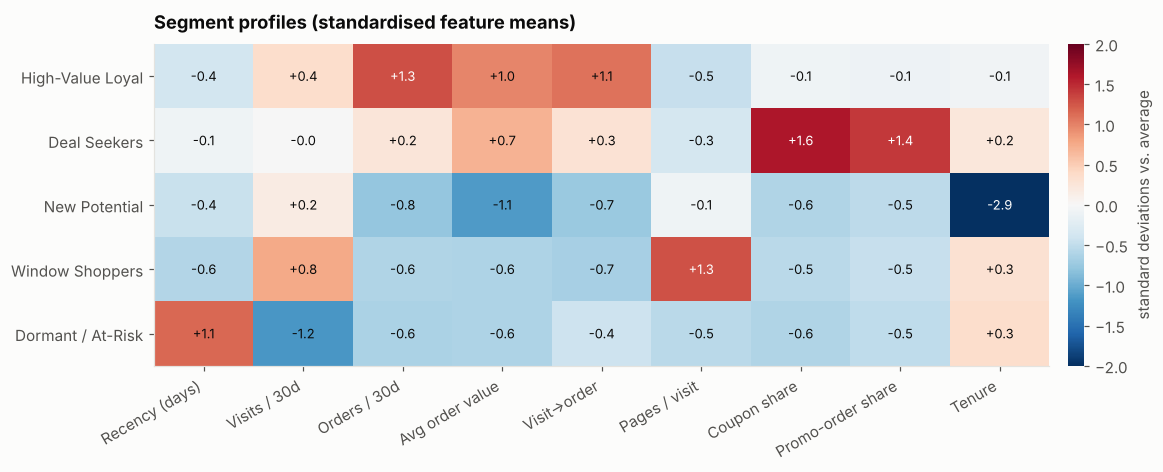

In [6]:
# Heat map of standardised feature means: how each segment differs from the average customer
z = pd.DataFrame(Xs, columns=seg.FEATURES, index=features.index).groupby(features["segment"]).mean().loc[ORDER]
labels_nice = ["Recency (days)", "Visits / 30d", "Orders / 30d", "Avg order value", "Visit→order",
               "Pages / visit", "Coupon share", "Promo-order share", "Tenure"]
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(labels_nice)), labels_nice, rotation=30, ha="right")
ax.set_yticks(range(len(ORDER)), ORDER)
ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = z.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 1.2 else ps.TEXT)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("standard deviations vs. average", color=ps.TEXT_2)
cb.outline.set_visible(False)
ax.set_title("Segment profiles (standardised feature means)")
ps.save(fig, "03_segment_profiles")

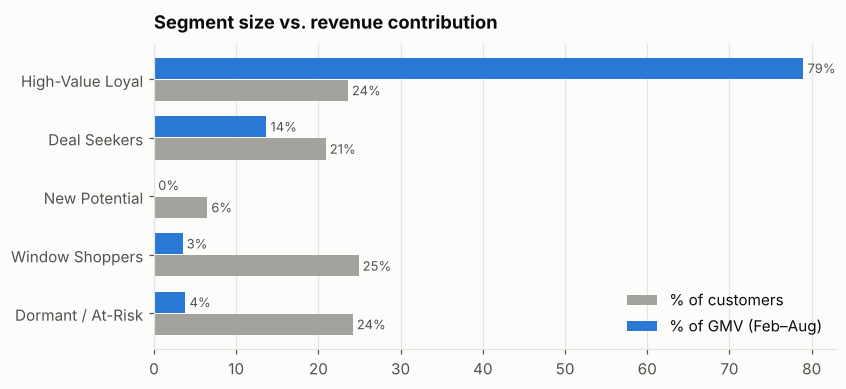

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(ORDER))
ax.barh(y + 0.19, profile["share_of_customers_pct"], 0.36, color=ps.CONTEXT, label="% of customers")
ax.barh(y - 0.19, profile["share_of_gmv_pct"], 0.36, color=ps.BLUE, label="% of GMV (Feb–Aug)")
for yi, (c, g) in enumerate(zip(profile["share_of_customers_pct"], profile["share_of_gmv_pct"])):
    ax.text(c + 0.5, yi + 0.19, f"{c:.0f}%", va="center", fontsize=8.5, color=ps.TEXT_2)
    ax.text(g + 0.5, yi - 0.19, f"{g:.0f}%", va="center", fontsize=8.5, color=ps.TEXT_2)
ax.set_yticks(y, ORDER)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right")
ax.set_title("Segment size vs. revenue contribution")
ps.save(fig, "03_segment_size_vs_gmv")

## 4. Who are they? (demographics)

In [8]:
demo = features[["segment"]].join(customers.set_index("customer_id")[["age_group", "city_tier"]])
age_mix = pd.crosstab(demo["segment"], demo["age_group"], normalize="index").loc[ORDER].mul(100).round(0)
tier_mix = pd.crosstab(demo["segment"], demo["city_tier"], normalize="index").loc[ORDER].mul(100).round(0)
display(age_mix)
display(tier_mix)

age_group,18-24,25-29,30-34,35-44,45+
segment,,,,,
High-Value Loyal,17.0,28.0,27.0,19.0,8.0
Deal Seekers,32.0,30.0,17.0,12.0,9.0
New Potential,28.0,32.0,20.0,13.0,8.0
Window Shoppers,30.0,29.0,20.0,13.0,7.0
Dormant / At-Risk,16.0,20.0,23.0,24.0,18.0


city_tier,Tier 1,Tier 2,Tier 3,Tier 4+
segment,,,,
High-Value Loyal,30.0,32.0,23.0,15.0
Deal Seekers,15.0,28.0,31.0,26.0
New Potential,25.0,32.0,27.0,16.0
Window Shoppers,21.0,30.0,29.0,20.0
Dormant / At-Risk,21.0,30.0,26.0,23.0


## 5. Targeting decision

| Segment | Profile | Action |
|---|---|---|
| **High-Value Loyal** | Frequent buyers, highest order value, rarely use coupons | Protect margin — **no coupons**; VIP service / early access instead |
| **Deal Seekers** | Buy mostly with coupons and in mega-sales, low order value | **Target**: coupons change *when* and *whether* they buy |
| **New Potential** | Joined in the last ~2 months, browsing actively but **no first order yet** | **Target**: a first-order coupon converts interest into a first purchase |
| **Window Shoppers** | Visit often, browse deeply, almost never buy | Not coupons first — fix the product page / recommendations (test separately) |
| **Dormant / At-Risk** | Have not visited in months | Low-cost win-back messages, not paid coupons |

**Deal Seekers + New Potential** were chosen for the coupon program, launched 2023-09-01 with a random
20% **holdout** so the effect could be measured (notebook 04).

In [9]:
program = con.execute("SELECT * FROM coupon_program").df()
target_ids = set(features.index[features["segment"].isin(seg.TARGET_SEGMENTS)])
print(f"Customers in target segments: {len(target_ids):,}")
print("Program roster matches the model output:", target_ids == set(program["customer_id"]))
program.groupby(["segment_at_launch", "group"]).size().unstack()

Customers in target segments: 3,768
Program roster matches the model output: True


group,control,treatment
segment_at_launch,,
Deal Seekers,606,2270
New Potential,165,727


## 6. Sanity check against the generator's answer key
Because the data is synthetic, we know each customer's *true* behavioural type. This check is done
**after** the model is final and is never used as an input.

In [10]:
key = pd.read_csv("../data/_answer_key_segments.csv").set_index("customer_id")
true = key.loc[features.index, "true_segment"]
print(f"Adjusted Rand Index vs. true segments: {adjusted_rand_score(true, features['segment']):.2f}")
pd.crosstab(features["segment"], true, normalize="index").loc[ORDER].mul(100).round(0)

Adjusted Rand Index vs. true segments: 0.45


true_segment,deal_seeker,dormant,loyal_high_value,new_potential,window_shopper
segment,,,,,
High-Value Loyal,20.0,4.0,48.0,27.0,0.0
Deal Seekers,73.0,4.0,2.0,13.0,8.0
New Potential,13.0,0.0,4.0,69.0,15.0
Window Shoppers,5.0,0.0,0.0,5.0,89.0
Dormant / At-Risk,23.0,69.0,2.0,5.0,1.0


The model recovers the main behavioural types (ARI ≈ 0.45 — reasonable for noisy behaviour data where
many customers have only one or two orders). Window Shoppers, Deal Seekers and New Potential are recovered
well (69–89% purity). The main confusions are understandable: new customers who already buy a lot look
like High-Value Loyal, and some deal seekers who were inactive outside the 618 sale look dormant.